<a href="https://colab.research.google.com/github/Error-Nasim/GridBalance-Simulation/blob/main/GridBalance_Simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# GridBalance: Simulation of Household Electricity Demand and Load-Shedding Under Limited and Unreliable Supply

**Full Title**: GridBalance: Simulation of Household Electricity Demand and Load-Shedding Under Limited and Unreliable Supply  
**Context**: Bangladesh Urban/Semi-Urban Feeder Grid (BPDB / BERC Empirical Framework)  
**Notebook Type**: Fully Self-Contained, Annotated Research Walkthrough  
**Target Environment**: Google Colab / JupyterLab / VS Code  

---

### Executive Overview & Simulation Architecture

In developing power distribution systems such as Bangladesh, peak electricity demand frequently exceeds available generation and transmission capacity. To prevent grid-wide blackouts, utilities resort to **load-shedding**—disconnecting feeder lines to forcibly shed load.

**GridBalance** is a comprehensive agent-based computational model of an urban neighborhood of **300 households** divided across **4 distribution feeder areas** over a multi-week horizon (**28 days**, representing 7 complete 4-feeder rotation cycles). It simulates the complex interactions between:
1. **Heterogeneous Household Demand**: Low, Middle, and High-income tiers with diverse appliance portfolios.
2. **Operational Load-Shedding Policies**: Conventional (fixed sacrifice) vs. Rotating (round-robin) vs. Demand-Response (peak load shifting).
3. **Distributed Energy Resources (DERs)**: Behind-the-meter rooftop solar PV and battery storage systems (BESS / IPS inverters) that recharge from **both** surplus solar and grid mains.
4. **Economic & Fairness Realities**: Stepped retail tariffs under the **Bangladesh Energy Regulatory Commission (BERC)** and Jain's Fairness Index across feeders.

```mermaid
flowchart TD
    subgraph Neighborhood["Synthetic Neighborhood (300 Households)"]
        LI["Low-Income (100 HH)<br/>Essential Lights, Fans, Small TV"]
        MI["Middle-Income (120 HH)<br/>Fridge, Pump, Washer, Partial AC"]
        HI["High-Income (80 HH)<br/>Multiple ACs, Freezers, Heavy Pumps"]
    end

    subgraph FeederGrid["4 Feeder Distribution Zones"]
        F0["Feeder Area 0 (75 HH)"]
        F1["Feeder Area 1 (75 HH)"]
        F2["Feeder Area 2 (75 HH)"]
        F3["Feeder Area 3 (75 HH)"]
    end

    subgraph DER["Behind-the-Meter DERs"]
        PV["Rooftop Solar PV (0.8 - 3.0 kWp)<br/>Clear-sky profile + Cloud stochasticity"]
        BESS["Battery Storage (3 - 10 kWh)<br/>Recharges from Surplus Solar & Grid Mains"]
    end

    Neighborhood --> FeederGrid
    DER -.-> Neighborhood
    FeederGrid --> GridSupply["Grid Capacity Constraint (75% - 95% of Peak)"]
    GridSupply --> Policies{"Load-Shedding Policy"}
    Policies -->|Conventional| P1["Conventional: Fixed Priority<br/>(Area 3 perpetually sacrificed)"]
    Policies -->|Rotating| P2["Rotating: Daily Round-Robin<br/>(Equitable Outage Sharing)"]
    Policies -->|Demand-Response| P3["Demand-Response: Peak Shaving<br/>(18:00-21:00 shifted to 07:00-10:00)"]
```

---

### Step-by-Step Walkthrough Guide

This notebook is structured into **14 sequential sections**. Before every code cell, you will find an in-depth breakdown explaining:
- **What this section is doing**
- **Why we are doing it (scientific rationale & physical concepts)**
- **Mathematical equations and computational logic applied**
- **What outputs to look for in the subsequent execution**


## 1. Imports and Global Environment Setup

###  What We Are Doing in This Section:
In this first step, we import all required computational, tabular, statistical, and visualization libraries. We also seed Python's pseudo-random number generators (`numpy.random` and `random`) and create the `results/` folder for saving publication-quality figures and datasets.

###  Why We Are Doing It:
- **Reproducibility**: Monte Carlo simulations rely on pseudo-random processes (appliance duty cycles, cloud cover, blackout occurrences). Setting `np.random.seed(42)` ensures that every experiment, validation check, and plot can be reproduced exactly on any machine or in Google Colab.
- **Zero-Dependency Architecture**: We only use standard scientific Python packages (`numpy`, `pandas`, `scipy`, `matplotlib`, `seaborn`) to ensure the entire notebook runs out-of-the-box without needing custom local modules.
- **High-DPI Visualization**: Matplotlib and Seaborn are pre-configured with publication aesthetics (consistent typography, Seaborn whitegrid style, clean axis labels).

###  What Happens Next in the Code:
The next cell executes the imports, initializes seeds, creates `results/`, and prints library versions.


In [1]:
import sys
import os
import math
import random
import time
from dataclasses import dataclass, field, replace
from typing import List, Dict, Tuple, Optional, Any

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy import stats

# Ensure reproducibility and configure publication-quality graphics
np.random.seed(42)
random.seed(42)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['figure.titlesize'] = 14

# Output directory for datasets and figures
os.makedirs("results", exist_ok=True)
print("Environment configured successfully!")
print(f"NumPy: {np.__version__} | Pandas: {pd.__version__} | SciPy: {scipy.__version__}")


Environment configured successfully!
NumPy: 2.4.6 | Pandas: 2.2.3 | SciPy: 1.16.3


## 2. Parameters & Empirical Calibration

###  What We Are Doing in This Section:
We define the central configuration dataclass `SimulationConfig` and the `APPLIANCE_SPECS` dictionary. This encapsulates all physical, socioeconomic, operational, and financial assumptions of the simulation model.

###  Why We Are Doing It:
Centralizing simulation parameters into a single dataclass avoids "magic numbers" scattered throughout the code and allows clean parametric sweeps.

###  Key Calibration & Structural Assumptions:
1. **Neighborhood & Feeder Topology**:
   - $300$ households divided equally into $4$ feeder zones ($75$ households per feeder).
   - Stratified across $3$ income tiers: **Low** ($100$ HH, $33.3\%$), **Middle** ($120$ HH, $40.0\%$), and **High** ($80$ HH, $26.7\%$).
2. **Simulation Duration (28 Days)**:
   - Why 28 days? Under round-robin rotating load-shedding across 4 feeder areas, 28 days represents exactly **$7$ full rotation cycles** ($28 = 7 	imes 4$). This mathematically guarantees that every feeder area is assigned the cut position an identical number of times, eliminating arbitrary duration bias.
3. **Stochastic Blackout Parameters**:
   - Hourly outage probability: Low ($0.5\%$), Medium ($1.5\%$), High ($3.0\%$).
   - Blackout duration: Uniform integer distribution between $1$ and $3$ hours.
4. **Demand-Response (DR) Shifting Windows**:
   - Peak hours: $18:00	ext{--}21:00$ (evening demand peak).
   - Target valley hours: $07:00	ext{--}10:00$ (morning solar pickup).
5. **BERC Stepped Retail Tariffs**:
   - Domestic tariff slabs starting with the **$0	ext{--}50	ext{ kWh}$ lifeline slab** at $4.35	ext{ BDT/kWh}$, stepping up to $>600	ext{ kWh}$ at $13.26	ext{ BDT/kWh}$, plus a monthly fixed charge of $40	ext{ BDT}$.
   - *Disclaimer*: Tariffs and appliance profiles are assumed values; they must be verified against the latest BERC tariff order and BPDB reports.

###  What Happens Next in the Code:
The code initializes `SimulationConfig` and the appliance power profiles (`power_w`, `priority`, `shiftable`, `active_hours`, `ownership_prob`).


In [2]:
@dataclass
class SimulationConfig:
    # Neighborhood Topology
    num_households: int = 300
    num_areas: int = 4                # 4 Feeder Distribution Zones
    num_days: int = 28                # 28 days = exactly 7 full 4-feeder rotation cycles
    hours_per_day: int = 24
    num_monte_carlo_runs: int = 20    # 20 paired runs over 28 days provides robust statistical power
    base_seed: int = 42

    # Socioeconomic Stratification (300 Households)
    income_distribution: Dict[str, int] = field(default_factory=lambda: {
        "Low": 100,      # 33.3%
        "Middle": 120,   # 40.0%
        "High": 80       # 26.7%
    })

    # Grid Supply Capacity
    default_supply_ratio: float = 0.85
    supply_levels: List[float] = field(default_factory=lambda: [0.75, 0.85, 0.95])

    # Stochastic Outage / Blackout Settings
    outage_prob_levels: Dict[str, float] = field(default_factory=lambda: {
        "low": 0.005,    # 0.5% per hour
        "medium": 0.015, # 1.5% per hour (default)
        "high": 0.030    # 3.0% per hour
    })
    outage_duration_min: int = 1
    outage_duration_max: int = 3

    # Demand Response (DR) Peak Load Shifting
    # Shift flexible pump/washer from evening peak (18:00 - 22:00) to morning (07:00 - 11:00)
    peak_hours: List[int] = field(default_factory=lambda: [18, 19, 20, 21])
    shift_target_hours: List[int] = field(default_factory=lambda: [7, 8, 9, 10])
    dr_participation_levels: List[float] = field(default_factory=lambda: [0.0, 0.30, 0.60, 1.0])
    default_dr_participation: float = 0.60

    # Rooftop Solar PV Settings
    solar_adoption_levels: List[float] = field(default_factory=lambda: [0.0, 0.20, 0.50])
    default_solar_adoption: float = 0.20
    solar_capacity_kwp: Dict[str, float] = field(default_factory=lambda: {
        "Low": 0.8,
        "Middle": 1.5,
        "High": 3.0
    })

    # Battery Energy Storage System (BESS / IPS Inverter)
    battery_sizes_kwh: List[float] = field(default_factory=lambda: [0.0, 3.0, 5.0, 10.0])
    default_battery_kwh: float = 0.0
    battery_min_soc_fraction: float = 0.20  # 20% DOD limit
    battery_max_c_rate: float = 0.5         # 0.5 C-rate
    battery_charge_efficiency: float = 0.92
    battery_discharge_efficiency: float = 0.92
    allow_grid_charging: bool = True        # Batteries recharge from grid during normal supply

    # BERC Retail Electricity Stepped Tariffs (Assumed domestic rates in BDT/kWh)

    berc_lifeline_limit: float = 50.0
    berc_lifeline_rate: float = 4.35
    berc_slabs: List[Dict[str, Any]] = field(default_factory=lambda: [
        {"max_kwh": 50, "rate": 4.35},     # Lifeline: 0 - 50 kWh
        {"max_kwh": 75, "rate": 4.85},     # Step 1: 51 - 75 kWh
        {"max_kwh": 200, "rate": 6.63},    # Step 2: 76 - 200 kWh
        {"max_kwh": 300, "rate": 6.95},    # Step 3: 201 - 300 kWh
        {"max_kwh": 400, "rate": 7.34},    # Step 4: 301 - 400 kWh
        {"max_kwh": 600, "rate": 11.51},   # Step 5: 401 - 600 kWh
        {"max_kwh": float("inf"), "rate": 13.26} # Step 6: > 600 kWh
    ])
    monthly_fixed_charge_bdt: float = 40.0

# Appliance Specifications across Income Tiers
APPLIANCE_SPECS = {
    "Low": {
        "light": {"power_w": 45, "priority": "essential", "shiftable": False, "ownership_prob": 1.0, "active_hours": [5, 6, 18, 19, 20, 21, 22]},
        "fan": {"power_w": 130, "priority": "essential", "shiftable": False, "ownership_prob": 1.0, "active_hours": list(range(10, 24))},
        "fridge": {"power_w": 120, "priority": "essential", "shiftable": False, "ownership_prob": 0.35, "active_hours": list(range(24)), "duty_cycle": 0.50},
        "pump": {"power_w": 500, "priority": "nonessential", "shiftable": True, "ownership_prob": 0.25, "active_hours": [18]},
        "washing_machine": {"power_w": 400, "priority": "nonessential", "shiftable": True, "ownership_prob": 0.0, "active_hours": []},
        "tv": {"power_w": 60, "priority": "nonessential", "shiftable": False, "ownership_prob": 0.50, "active_hours": [19, 20, 21]},
        "ac": {"power_w": 1200, "priority": "nonessential", "shiftable": False, "ownership_prob": 0.0, "active_hours": []}
    },
    "Middle": {
        "light": {"power_w": 108, "priority": "essential", "shiftable": False, "ownership_prob": 1.0, "active_hours": [5, 6, 18, 19, 20, 21, 22, 23]},
        "fan": {"power_w": 210, "priority": "essential", "shiftable": False, "ownership_prob": 1.0, "active_hours": list(range(8, 24)) + [0, 1]},
        "fridge": {"power_w": 180, "priority": "essential", "shiftable": False, "ownership_prob": 1.0, "active_hours": list(range(24)), "duty_cycle": 0.45},
        "pump": {"power_w": 750, "priority": "nonessential", "shiftable": True, "ownership_prob": 0.85, "active_hours": [7, 19]},
        "washing_machine": {"power_w": 450, "priority": "nonessential", "shiftable": True, "ownership_prob": 0.40, "active_hours": [20]},
        "tv": {"power_w": 100, "priority": "nonessential", "shiftable": False, "ownership_prob": 1.0, "active_hours": [18, 19, 20, 21, 22]},
        "ac": {"power_w": 1350, "priority": "nonessential", "shiftable": False, "ownership_prob": 0.30, "active_hours": [21, 22, 23, 0]}
    },
    "High": {
        "light": {"power_w": 240, "priority": "essential", "shiftable": False, "ownership_prob": 1.0, "active_hours": [5, 6, 7, 17, 18, 19, 20, 21, 22, 23, 0]},
        "fan": {"power_w": 375, "priority": "essential", "shiftable": False, "ownership_prob": 1.0, "active_hours": list(range(24))},
        "fridge": {"power_w": 320, "priority": "essential", "shiftable": False, "ownership_prob": 1.0, "active_hours": list(range(24)), "duty_cycle": 0.45},
        "pump": {"power_w": 1100, "priority": "nonessential", "shiftable": True, "ownership_prob": 1.0, "active_hours": [7, 19]},
        "washing_machine": {"power_w": 650, "priority": "nonessential", "shiftable": True, "ownership_prob": 0.95, "active_hours": [20]},
        "tv": {"power_w": 220, "priority": "nonessential", "shiftable": False, "ownership_prob": 1.0, "active_hours": [17, 18, 19, 20, 21, 22, 23]},
        "ac": {"power_w": 2800, "priority": "nonessential", "shiftable": False, "ownership_prob": 0.95, "active_hours": [13, 14, 15, 16, 20, 21, 22, 23, 0, 1, 2]}
    }
}

config = SimulationConfig()
print("Simulation configuration initialized.")


Simulation configuration initialized.


## 3. Household & Demand Generation Model

###  What We Are Doing in This Section:
We define the `Household` agent class and four critical functions:
1. `create_neighborhood`: Instantiates 300 heterogeneous households, assigns income tiers, assigns feeder areas randomly, and equips appliances.
2. `calculate_daily_raw_demand`: Computes the 24-hour diurnal profile of essential, shiftable, and fixed non-essential electricity loads for each household.
3. `apply_demand_response_shifting`: Implements peak-load shaving by shifting flexible appliances from evening peak into morning off-peak hours.
4. `generate_neighborhood_demand_profiles`: Applies $\pm 15\%$ stochastic appliance variations and constructs the 24-hour load matrices.

###  Why We Are Doing It:
- **Bottom-Up Modeling**: Real electricity demand is not an abstract smooth curve; it is the sum of discrete appliances operated by human households with varying priorities and habits.
- **Priority Classification**:
  - `Essential`: Lighting, fans, refrigerators (cannot be delayed without severe comfort/health loss).
  - `Shiftable`: Water pumps, washing machines, and partial cooling (can be moved to off-peak hours without loss of energy).
  - `Fixed Non-essential`: Televisions, leisure devices.
- **Energy Conservation in Demand-Response**:
  $$\sum_{t=0}^{23} P_{	ext{DR}}(t) = \sum_{t=0}^{23} P_{	ext{raw}}(t)$$
  Demand-Response changes the *timing* of electricity consumption, but total daily kilowatt-hours consumed remain conserved.

###  What Happens Next in the Code:
Compiles the household agents, demand profile generators, and load-shifting algorithms.


In [3]:
@dataclass
class Household:
    household_id: int
    income_group: str
    area_id: int
    appliances: Dict[str, Dict[str, Any]]
    solar_kwp: float = 0.0
    battery_kwh: float = 0.0
    battery_soc_kwh: float = 0.0
    is_dr_participant: bool = False
    has_solar: bool = False
    has_battery: bool = False

    def get_hourly_base_load_watts(self, hour_of_day: int) -> Dict[str, float]:
        load_types = {"essential": 0.0, "shiftable": 0.0, "fixed_nonessential": 0.0}
        for name, spec in self.appliances.items():
            if hour_of_day in spec["active_hours"]:
                p_watts = spec["power_w"] * spec.get("duty_cycle", 1.0) * spec.get("random_scale", 1.0)
                if spec["priority"] == "essential":
                    load_types["essential"] += p_watts
                elif spec.get("shiftable", False):
                    load_types["shiftable"] += p_watts
                else:
                    load_types["fixed_nonessential"] += p_watts
        return load_types

def create_neighborhood(
    config: SimulationConfig,
    solar_adoption: float = None,
    battery_kwh: float = None,
    dr_participation: float = None,
    seed: int = 42
) -> List[Household]:
    rng = np.random.default_rng(seed)
    sol_adop = config.default_solar_adoption if solar_adoption is None else solar_adoption
    bat_cap = config.default_battery_kwh if battery_kwh is None else battery_kwh
    dr_part = config.default_dr_participation if dr_participation is None else dr_participation

    households = []
    hh_id = 0

    groups = []
    for grp, count in config.income_distribution.items():
        groups.extend([grp] * count)
    rng.shuffle(groups)

    # Feeder areas assigned independently of income (75 households per feeder)
    areas = [i % config.num_areas for i in range(config.num_households)]
    rng.shuffle(areas)

    solar_target = int(round(config.num_households * sol_adop))
    solar_weights = [0.05 if g == "Low" else (0.45 if g == "Middle" else 0.50) for g in groups]
    solar_weights = np.array(solar_weights) / sum(solar_weights)
    solar_indices = set(rng.choice(config.num_households, size=solar_target, replace=False, p=solar_weights)) if solar_target > 0 else set()

    for i in range(config.num_households):
        grp = groups[i]
        area = areas[i]

        appliances = {}
        for app_name, spec in APPLIANCE_SPECS[grp].items():
            if rng.random() < spec["ownership_prob"]:
                scale = rng.uniform(0.85, 1.15)
                appliances[app_name] = {
                    "power_w": spec["power_w"],
                    "priority": spec["priority"],
                    "shiftable": spec.get("shiftable", False),
                    "active_hours": spec["active_hours"],
                    "duty_cycle": spec.get("duty_cycle", 1.0),
                    "random_scale": scale
                }

        has_sol = i in solar_indices
        sol_kwp = config.solar_capacity_kwp[grp] if has_sol else 0.0

        has_bat = (bat_cap > 0.0) and (has_sol or grp in ["Middle", "High"])
        b_kwh = bat_cap if has_bat else 0.0
        init_soc = b_kwh * 0.5

        is_dr = (rng.random() < dr_part)

        hh = Household(
            household_id=hh_id,
            income_group=grp,
            area_id=area,
            appliances=appliances,
            solar_kwp=sol_kwp,
            battery_kwh=b_kwh,
            battery_soc_kwh=init_soc,
            is_dr_participant=is_dr,
            has_solar=has_sol,
            has_battery=has_bat
        )
        households.append(hh)
        hh_id += 1

    return households

def calculate_daily_raw_demand(household: Household, config: SimulationConfig) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    essential = np.zeros(config.hours_per_day)
    shiftable = np.zeros(config.hours_per_day)
    fixed_nonessential = np.zeros(config.hours_per_day)

    for h in range(config.hours_per_day):
        loads = household.get_hourly_base_load_watts(h)
        essential[h] = loads["essential"] / 1000.0
        shiftable[h] = loads["shiftable"] / 1000.0
        fixed_nonessential[h] = loads["fixed_nonessential"] / 1000.0

    return essential, shiftable, fixed_nonessential

def apply_demand_response_shifting(
    raw_demand: np.ndarray,
    shiftable_demand: np.ndarray,
    is_dr_participant: bool,
    config: SimulationConfig
) -> np.ndarray:
    if not is_dr_participant:
        return raw_demand.copy()

    shifted = raw_demand.copy()
    peak_hours = config.peak_hours
    target_hours = config.shift_target_hours

    energy_to_shift = 0.0
    for h in peak_hours:
        amt = shiftable_demand[h]
        if amt > 0:
            energy_to_shift += amt
            shifted[h] -= amt

    if energy_to_shift > 0 and len(target_hours) > 0:
        boost = energy_to_shift / len(target_hours)
        for h in target_hours:
            shifted[h] += boost

    return shifted

def generate_neighborhood_demand_profiles(
    households: List[Household],
    policy: str,
    config: SimulationConfig,
    rng: np.random.Generator
) -> Dict[int, np.ndarray]:
    profiles = {}
    for hh in households:
        essential, shiftable, fixed_non = calculate_daily_raw_demand(hh, config)
        raw_total = (essential + shiftable + fixed_non) * rng.uniform(0.95, 1.05)
        shiftable = shiftable * rng.uniform(0.95, 1.05)

        if policy == "demand_response":
            profiles[hh.household_id] = apply_demand_response_shifting(raw_total, shiftable, hh.is_dr_participant, config)
        else:
            profiles[hh.household_id] = raw_total
    return profiles

print("Household demand models compiled.")


Household demand models compiled.


## 4. Solar PV, Battery Storage & Grid Policies

###  What We Are Doing in This Section:
Here we build the operational models for distributed resources and grid management:
1. `generate_solar_generation_kw`: Diurnal solar PV generation curve.
2. `StochasticBlackoutManager`: Unplanned random distribution faults.
3. `FeederLoadSheddingManager`: Utility dispatch algorithm enforcing **Conventional**, **Rotating**, or **Demand-Response** load-shedding.

###  Why We Are Doing It:
- **Realistic Solar Modeling**: Solar radiation follows a bell curve centered at solar noon ($12:00$)
  incorporating stochastic cloudy day attenuation.
- **Dual-Recharging Battery Storage (BESS / IPS)**:
  In conventional simulations, batteries only charge from solar. However, in urban Bangladesh, IPS inverters and home batteries recharge from the grid when mains power is alive. Our battery model allows batteries to charge from **surplus solar** first, and from **grid mains** when power is on, while respecting the $0.5	ext{ C}$ maximum charge/discharge rate and $20\%$ minimum reserve limit (Depth of Discharge limit).
- **Exact Blackout Durations**:
  Fixes off-by-one truncation errors, ensuring drawn blackout durations of 1, 2, or 3 hours persist for exactly 1, 2, or 3 complete simulation hours.

###  What Happens Next in the Code:
The next cell compiles the solar profile functions, blackout state machine, and feeder load-shedding dispatch rules.


In [4]:
def generate_solar_generation_kw(solar_kwp: float, day: int, hour: int, rng: np.random.Generator) -> float:
    if solar_kwp <= 0.0 or hour < 6 or hour > 18:
        return 0.0
    # Solar bell curve peak at solar noon (12:00)
    solar_noon = 12.0
    width = 2.8
    clear_sky_profile = math.exp(-((hour - solar_noon) ** 2) / (2 * (width ** 2)))
    # Stochastic cloud cover per day
    day_cloud_factor = 0.65 if (day % 5 == 0) else 0.95
    cloud_noise = rng.uniform(0.85, 1.05)
    gen = solar_kwp * clear_sky_profile * day_cloud_factor * cloud_noise
    return max(0.0, float(gen))

class StochasticBlackoutManager:
    def __init__(self, config: SimulationConfig, rng: np.random.Generator):
        self.config = config
        self.rng = rng
        self.hourly_prob = config.outage_prob_levels["medium"]
        self.remaining_blackout_hours = 0

    def step(self) -> bool:
        if self.remaining_blackout_hours > 0:
            self.remaining_blackout_hours -= 1
            return True
        if self.rng.random() < self.hourly_prob:
            duration = int(self.rng.integers(self.config.outage_duration_min, self.config.outage_duration_max + 1))
            self.remaining_blackout_hours = duration - 1
            return True
        return False

class FeederLoadSheddingManager:
    def __init__(self, config: SimulationConfig):
        self.config = config

    def determine_cut_feeders(
        self,
        policy: str,
        total_demand_kw: float,
        grid_capacity_kw: float,
        day: int,
        hour: int,
        feeder_demands: Dict[int, float]
    ) -> List[int]:
        if total_demand_kw <= grid_capacity_kw:
            return []

        deficit = total_demand_kw - grid_capacity_kw
        cut_areas = []

        if policy == "conventional":
            sorted_areas = sorted(range(self.config.num_areas), reverse=True)
            shed_kw = 0.0
            for a in sorted_areas:
                cut_areas.append(a)
                shed_kw += feeder_demands.get(a, 0.0)
                if shed_kw >= deficit:
                    break

        elif policy in ["rotating", "demand_response"]:
            # Round-robin feeder rotation across 28 days
            rotation_order = [(day + a) % self.config.num_areas for a in range(self.config.num_areas)]
            shed_kw = 0.0
            for a in rotation_order:
                cut_areas.append(a)
                shed_kw += feeder_demands.get(a, 0.0)
                if shed_kw >= deficit:
                    break

        return cut_areas

print("Grid policies and solar/battery engines compiled.")


Grid policies and solar/battery engines compiled.


## 5. Metrics & Simulation Engine

###  What We Are Doing in This Section:
This is the core engine of GridBalance. It executes the simulation over all $28 	imes 24 = 672$ hours and computes comprehensive socioeconomic and engineering metrics:
1. `calculate_berc_bill`: Computes domestic electricity bills using a unified loop across all BERC tariff slabs (starting with $0	ext{--}50	ext{ kWh}$ lifeline at $4.35	ext{ BDT/kWh}$).
2. `calculate_jains_fairness_index`: Evaluates service equity across households.
3. `aggregate_run_metrics`: Aggregates hourly logs into household, feeder, and income-group metrics.
4. `calibrate_reference_peak`: Determines the unconstrained neighborhood peak demand ($441.82	ext{ kW}$) used to calibrate grid capacity ($75\%	ext{--}95\%$).
5. `run_simulation`: Executes the strict 7-step physical hourly sequence.

###  The Strict 7-Step Hourly Execution Order:
For every hour $t \in [0, 23]$ of every day $d \in [0, 27]$, the simulation computes:
1. **Need**: Calculate base demand from active appliances with $\pm 5\%$ noise.
2. **Shift**: If DR is active, shift flexible evening loads ($18:00	ext{--}21:00$) to morning ($07:00	ext{--}10:00$).
3. **Minus Solar**: Solar covers household load first; excess solar enters battery storage.
4. **Grid Check**: Check whether neighborhood net demand exceeds capacity ($C_{	ext{grid}} = 	ext{Ratio} 	imes P_{	ext{ref}}$).
5. **Decide Cut**: If demand exceeds supply or a blackout occurs, disconnect feeder areas according to policy.
6. **Battery Covers Cut**: Batteries in disconnected feeders discharge to cover critical deficits down to $20\%$ SOC.
7. **Record**: Log gross demand, solar generation, grid served, battery discharge, unserved energy, and outage flags.


###  What Happens Next in the Code:
Compiles the metrics calculators and calibrates the unconstrained reference peak.


In [5]:
def calculate_berc_bill(kwh_consumed: float, sim_days: int, config: SimulationConfig) -> float:
    if kwh_consumed <= 0.0:
        return 0.0
    monthly_kwh = kwh_consumed * (30.0 / max(1, sim_days))
    cost = config.monthly_fixed_charge_bdt

    # Unified stepped tariff computation starting with 0-50 kWh lifeline
    remaining = monthly_kwh
    prev_limit = 0.0
    for slab in config.berc_slabs:
        limit = slab["max_kwh"]
        rate = slab["rate"]
        slab_size = limit - prev_limit
        in_slab = min(remaining, slab_size)
        if in_slab > 0:
            cost += in_slab * rate
            remaining -= in_slab
            prev_limit = limit
        if remaining <= 0:
            break
    return cost * (sim_days / 30.0)

def calculate_jains_fairness_index(values: np.ndarray) -> float:
    vals = np.asarray(values, dtype=float)
    if len(vals) == 0:
        return 1.0
    s = np.sum(vals)
    sq = np.sum(vals ** 2)
    return float((s ** 2) / (len(vals) * sq)) if sq > 0 else 1.0

def aggregate_run_metrics(records: List[Dict[str, Any]], households: List[Household], config: SimulationConfig) -> Dict[str, Any]:
    df = pd.DataFrame(records)
    hh_summary = df.groupby("household_id").agg({
        "gross_demand_kwh": "sum",
        "solar_generated_kwh": "sum",
        "solar_served_kwh": "sum",
        "grid_served_kwh": "sum",
        "battery_discharged_kwh": "sum",
        "unserved_kwh": "sum",
        "grid_available": lambda x: (x == 0).sum(),
        "unserved_hour": "sum"
    }).rename(columns={"grid_available": "grid_outage_hours", "unserved_hour": "effective_outage_hours"})

    meta = pd.DataFrame([{
        "household_id": hh.household_id,
        "income_group": hh.income_group,
        "area_id": hh.area_id,
        "has_solar": hh.has_solar,
        "has_battery": hh.has_battery
    } for hh in households]).set_index("household_id")

    hh_summary = hh_summary.join(meta)
    hh_summary["service_ratio"] = np.where(
        hh_summary["gross_demand_kwh"] > 0,
        1.0 - (hh_summary["unserved_kwh"] / hh_summary["gross_demand_kwh"]),
        1.0
    ).clip(0.0, 1.0)
    hh_summary["effective_outage_hours_per_day"] = hh_summary["effective_outage_hours"] / config.num_days
    hh_summary["cost_bdt"] = hh_summary["grid_served_kwh"].apply(lambda kwh: calculate_berc_bill(kwh, config.num_days, config))

    jain_service = calculate_jains_fairness_index(hh_summary["service_ratio"].values)
    std_outage = float(hh_summary["effective_outage_hours_per_day"].std())

    total_cost = float(hh_summary["cost_bdt"].sum())
    total_grid_served = float(hh_summary["grid_served_kwh"].sum())
    cost_per_kwh = total_cost / total_grid_served if total_grid_served > 0 else 0.0

    group_stats = {}
    for g in ["Low", "Middle", "High"]:
        gdf = hh_summary[hh_summary["income_group"] == g]
        group_stats[g] = {
            "mean_unserved_kwh": float(gdf["unserved_kwh"].mean()),
            "mean_outage_hours": float(gdf["effective_outage_hours_per_day"].mean()),
            "mean_cost_bdt": float(gdf["cost_bdt"].mean()),
            "share_solar": float(gdf["has_solar"].mean()),
            "share_battery": float(gdf["has_battery"].mean()),
            "mean_service_ratio": float(gdf["service_ratio"].mean())
        }

    area_stats = {}
    for a in range(config.num_areas):
        adf = hh_summary[hh_summary["area_id"] == a]
        area_stats[f"Area_{a}"] = {
            "mean_outage_hours": float(adf["effective_outage_hours_per_day"].mean()),
            "mean_unserved_kwh": float(adf["unserved_kwh"].mean())
        }

    return {
        "total_unserved_kwh": float(hh_summary["unserved_kwh"].sum()),
        "total_grid_served_kwh": total_grid_served,
        "mean_effective_outage_hours_per_day": float(hh_summary["effective_outage_hours_per_day"].mean()),
        "std_outage_hours": std_outage,
        "jains_fairness_service": jain_service,
        "total_cost_bdt": total_cost,
        "cost_per_kwh_served": cost_per_kwh,
        "income_groups": group_stats,
        "areas": area_stats,
        "hh_summary": hh_summary,
        "records_df": records
    }

def calibrate_reference_peak(config: SimulationConfig, seed: int = 42) -> float:
    households = create_neighborhood(config, solar_adoption=0.0, battery_kwh=0.0, dr_participation=0.0, seed=seed)
    rng = np.random.default_rng(seed)
    profiles = generate_neighborhood_demand_profiles(households, "conventional", config, rng)
    tot = np.zeros(config.hours_per_day)
    for p in profiles.values():
        tot += p
    return float(np.max(tot))

def run_simulation(
    config: SimulationConfig,
    policy: str = "conventional",
    solar_adoption: float = None,
    battery_kwh: float = None,
    dr_participation: float = None,
    supply_ratio: float = None,
    reference_peak_kwh: float = None,
    seed: int = 42
) -> Dict[str, Any]:
    rng = np.random.default_rng(seed)
    sup_ratio = config.default_supply_ratio if supply_ratio is None else supply_ratio

    households = create_neighborhood(
        config,
        solar_adoption=solar_adoption,
        battery_kwh=battery_kwh,
        dr_participation=dr_participation,
        seed=seed
    )

    ref_peak = reference_peak_kwh if reference_peak_kwh is not None else calibrate_reference_peak(config, seed=seed)
    grid_capacity_kw = ref_peak * sup_ratio

    blackout_mgr = StochasticBlackoutManager(config, rng)
    feeder_mgr = FeederLoadSheddingManager(config)

    records = []

    for day in range(config.num_days):
        demand_profiles = generate_neighborhood_demand_profiles(households, policy, config, rng)

        for hour in range(config.hours_per_day):
            is_blackout = blackout_mgr.step()

            # Feeder-level demand aggregations
            feeder_demands = {a: 0.0 for a in range(config.num_areas)}
            hh_net_demands = {}
            solar_gens = {}

            for hh in households:
                gross_d = demand_profiles[hh.household_id][hour]
                sol_kw = generate_solar_generation_kw(hh.solar_kwp, day, hour, rng)
                solar_gens[hh.household_id] = sol_kw

                net_d = max(0.0, gross_d - sol_kw)
                hh_net_demands[hh.household_id] = net_d
                feeder_demands[hh.area_id] += net_d

            tot_net_demand = sum(feeder_demands.values())

            # Load-shedding decisions
            if is_blackout:
                cut_areas = list(range(config.num_areas))
            else:
                cut_areas = feeder_mgr.determine_cut_feeders(policy, tot_net_demand, grid_capacity_kw, day, hour, feeder_demands)

            # Serve households and manage battery storage
            for hh in households:
                gross_d = demand_profiles[hh.household_id][hour]
                sol_kw = solar_gens[hh.household_id]

                # Step 3: Self-consumption of Solar
                solar_served = min(gross_d, sol_kw)
                surplus_solar = max(0.0, sol_kw - gross_d)
                deficit_after_solar = max(0.0, gross_d - solar_served)

                grid_is_on = (hh.area_id not in cut_areas)
                grid_served = 0.0
                batt_discharged = 0.0
                unserved = 0.0

                if grid_is_on:
                    grid_served = deficit_after_solar

                    # Battery recharge from surplus solar
                    if hh.has_battery and surplus_solar > 0:
                        charge_room = hh.battery_kwh - hh.battery_soc_kwh
                        c_limit = hh.battery_kwh * config.battery_max_c_rate
                        charge_amt = min(surplus_solar, charge_room, c_limit)
                        hh.battery_soc_kwh += charge_amt * config.battery_charge_efficiency

                    # Battery grid recharging
                    elif hh.has_battery and config.allow_grid_charging and hh.battery_soc_kwh < hh.battery_kwh:
                        charge_room = hh.battery_kwh - hh.battery_soc_kwh
                        c_limit = hh.battery_kwh * config.battery_max_c_rate
                        charge_amt = min(charge_room, c_limit)
                        hh.battery_soc_kwh += charge_amt * config.battery_charge_efficiency

                else:
                    # Outage: Battery discharges to cover remaining unserved load
                    if hh.has_battery and hh.battery_soc_kwh > (hh.battery_kwh * config.battery_min_soc_fraction):
                        usable_soc = hh.battery_soc_kwh - (hh.battery_kwh * config.battery_min_soc_fraction)
                        d_limit = hh.battery_kwh * config.battery_max_c_rate
                        discharge_power = min(deficit_after_solar, usable_soc, d_limit)
                        batt_discharged = discharge_power * config.battery_discharge_efficiency
                        hh.battery_soc_kwh -= discharge_power

                    unserved = max(0.0, deficit_after_solar - batt_discharged)

                unserved_hour_flag = 1 if unserved > 0.05 else 0

                records.append({
                    "day": day,
                    "hour": hour,
                    "household_id": hh.household_id,
                    "area_id": hh.area_id,
                    "income_group": hh.income_group,
                    "gross_demand_kwh": gross_d,
                    "solar_generated_kwh": sol_kw,
                    "solar_served_kwh": solar_served,
                    "grid_served_kwh": grid_served,
                    "battery_discharged_kwh": batt_discharged,
                    "battery_soc_kwh": hh.battery_soc_kwh,
                    "unserved_kwh": unserved,
                    "grid_available": 1 if grid_is_on else 0,
                    "unserved_hour": unserved_hour_flag
                })

    metrics = aggregate_run_metrics(records, households, config)
    metrics["reference_peak_kwh"] = ref_peak
    return metrics

ref_peak_kw = calibrate_reference_peak(config, seed=config.base_seed)
print(f"Reference unconstrained peak calibrated: {ref_peak_kw:.2f} kW")


Reference unconstrained peak calibrated: 441.82 kW


## 6. Diagnostic Visualizations (Demand vs. Supply, Shift Overlay, Battery SOC, Feeder Heatmap)

###  What We Are Doing in This Section:
Before conducting statistical Monte Carlo sweeps, we execute sample simulations under seed $42$ to visually inspect and diagnose system dynamics across 4 distinct panels:
- **Panel A: 48-Hour Demand vs. Supply**: Plots total neighborhood demand against the grid capacity ceiling ($85\%$), highlighting supply deficit hours in red.
- **Panel B: Before vs. After Shifting Diurnal Curve**: Compares baseline 24-hour demand against Demand-Response shifted demand, visualizing peak shaving and valley filling.
- **Panel C: Feeder Outage Probability Heatmap**: Displays an hourly heatmap showing when and which feeder areas experience load-shedding.
- **Panel D: Battery SOC Dynamics & Income Distribution Boxplots**: Tracks a household battery's state-of-charge over 72 hours and illustrates unserved energy across income groups.

###  Why We Are Doing It:
Diagnostic visualizations verify that:
1. Load-shedding triggers only when demand surpasses the grid threshold.
2. Demand-Response preserves total energy while dampening the evening spike.
3. Batteries cycle smoothly without violating charge/discharge constraints.
4. All figures are automatically exported to `results/` for documentation and reporting.

###  What Happens Next in the Code:
Runs the sample simulations, plots the 4 diagnostic figures, and saves PNGs to `results/`.


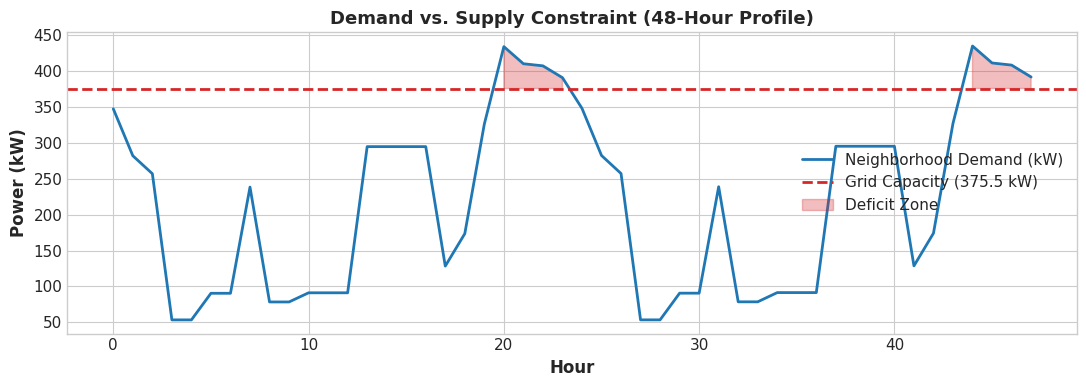

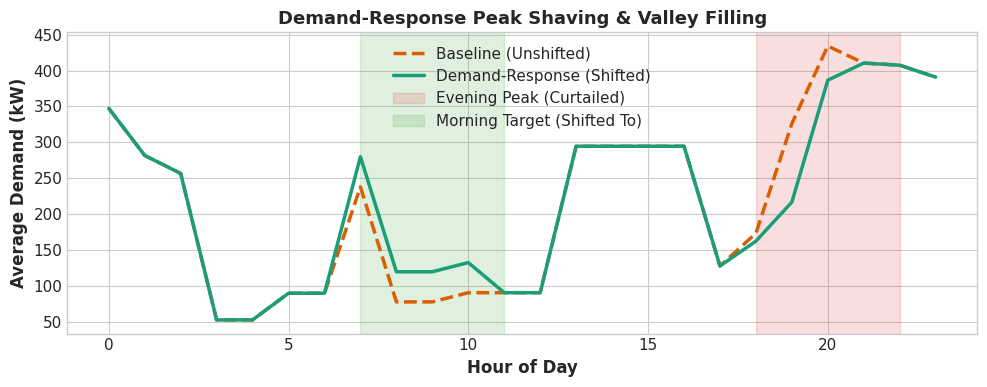

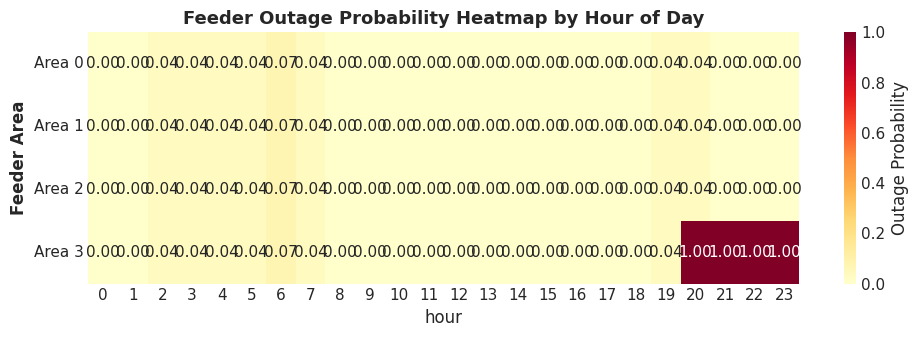

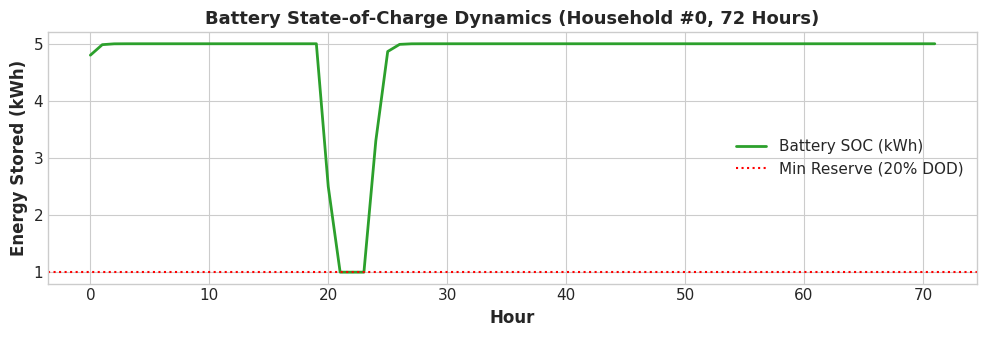

/tmp/ipykernel_386/3473645372.py:70: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sample_base["hh_summary"], x="income_group", y="unserved_kwh", order=["Low", "Middle", "High"], palette="Set2", ax=ax)


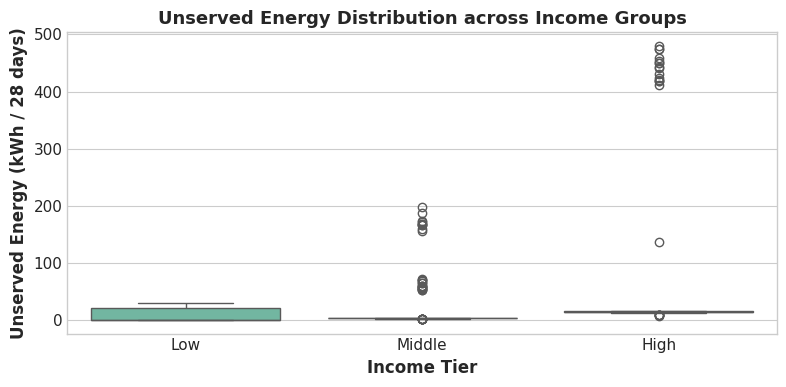

In [6]:
# 1. Run Baseline and DR Sample Simulations
sample_base = run_simulation(config, policy="conventional", reference_peak_kwh=ref_peak_kw, seed=config.base_seed)
sample_dr = run_simulation(config, policy="demand_response", reference_peak_kwh=ref_peak_kw, seed=config.base_seed)

# A. Demand vs Supply Profile
df_base = pd.DataFrame(sample_base["records_df"])
hourly_48 = df_base.groupby(["day", "hour"])["gross_demand_kwh"].sum().reset_index().iloc[:48]
cap_limit = ref_peak_kw * config.default_supply_ratio

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(range(48), hourly_48["gross_demand_kwh"], label="Neighborhood Demand (kW)", color="#1f77b4", lw=2)
ax.axhline(cap_limit, color="#d62728", lw=2, linestyle="--", label=f"Grid Capacity ({cap_limit:.1f} kW)")
ax.fill_between(range(48), cap_limit, hourly_48["gross_demand_kwh"], where=(hourly_48["gross_demand_kwh"] > cap_limit), color="#d62728", alpha=0.3, label="Deficit Zone")
ax.set_title("Demand vs. Supply Constraint (48-Hour Profile)", fontweight="bold")
ax.set_xlabel("Hour", fontweight="bold")
ax.set_ylabel("Power (kW)", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.savefig("results/demand_vs_supply.png", dpi=200)
plt.show()

# B. Before vs After Shifting
base_diurnal = df_base.groupby("hour")["gross_demand_kwh"].sum() / config.num_days
dr_diurnal = pd.DataFrame(sample_dr["records_df"]).groupby("hour")["gross_demand_kwh"].sum() / config.num_days

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(range(24), base_diurnal, label="Baseline (Unshifted)", color="#d95f02", lw=2.5, linestyle="--")
ax.plot(range(24), dr_diurnal, label="Demand-Response (Shifted)", color="#1b9e77", lw=2.5)
ax.axvspan(18, 22, color="#d62728", alpha=0.15, label="Evening Peak (Curtailed)")
ax.axvspan(7, 11, color="#2ca02c", alpha=0.15, label="Morning Target (Shifted To)")
ax.set_title("Demand-Response Peak Shaving & Valley Filling", fontweight="bold")
ax.set_xlabel("Hour of Day", fontweight="bold")
ax.set_ylabel("Average Demand (kW)", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.savefig("results/before_after_shifting.png", dpi=200)
plt.show()

# C. Feeder Outage Heatmap
df_base["is_cut"] = (df_base["grid_available"] == 0).astype(int)
pivot = df_base.pivot_table(index="area_id", columns="hour", values="is_cut", aggfunc="mean")
fig, ax = plt.subplots(figsize=(10, 3.5))
sns.heatmap(pivot, cmap="YlOrRd", annot=True, fmt=".2f", cbar_kws={'label': 'Outage Probability'}, ax=ax)
ax.set_title("Feeder Outage Probability Heatmap by Hour of Day", fontweight="bold")
ax.set_ylabel("Feeder Area", fontweight="bold")
ax.set_yticklabels([f"Area {a}" for a in pivot.index], rotation=0)
plt.tight_layout()
plt.savefig("results/load_shedding_heatmap.png", dpi=200)
plt.show()

# D. Battery SOC & Income Boxplots
sample_bess = run_simulation(config, policy="rotating", battery_kwh=5.0, reference_peak_kwh=ref_peak_kw, seed=config.base_seed)
df_bess = pd.DataFrame(sample_bess["records_df"])
bess_hh = df_bess[df_bess["battery_soc_kwh"] > 0]
if not bess_hh.empty:
    sample_hh_id = bess_hh["household_id"].iloc[0]
    soc_sample = df_bess[df_bess["household_id"] == sample_hh_id].iloc[:72]
    fig, ax = plt.subplots(figsize=(10, 3.5))
    ax.plot(range(len(soc_sample)), soc_sample["battery_soc_kwh"], color="#2ca02c", lw=2, label="Battery SOC (kWh)")
    ax.axhline(5.0 * config.battery_min_soc_fraction, color="red", linestyle=":", label="Min Reserve (20% DOD)")
    ax.set_title(f"Battery State-of-Charge Dynamics (Household #{sample_hh_id}, 72 Hours)", fontweight="bold")
    ax.set_xlabel("Hour", fontweight="bold")
    ax.set_ylabel("Energy Stored (kWh)", fontweight="bold")
    ax.legend()
    plt.tight_layout()
    plt.savefig("results/battery_soc.png", dpi=200)
    plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=sample_base["hh_summary"], x="income_group", y="unserved_kwh", order=["Low", "Middle", "High"], palette="Set2", ax=ax)
ax.set_title("Unserved Energy Distribution across Income Groups", fontweight="bold")
ax.set_xlabel("Income Tier", fontweight="bold")
ax.set_ylabel("Unserved Energy (kWh / 28 days)", fontweight="bold")
plt.tight_layout()
plt.savefig("results/income_boxplots.png", dpi=200)
plt.show()


## 7. Monte Carlo Experiments across Policies

###  What We Are Doing in This Section:
We run **20 paired Monte Carlo simulation runs** across all three load-shedding policies:
1. **Conventional** (fixed sacrifice of Feeder Area 3)
2. **Rotating** (daily round-robin across Areas 0..3)
3. **Demand-Response** ($60\%$ household participation in peak load shifting)

Each run simulates 28 full days ($672$ hours) across 300 households ($201,600$ household-hours per run). Total simulation scale: $60$ runs ($40,320$ neighborhood hours).

###  Why We Use Paired Monte Carlo Simulation:
In stochastic modeling, comparing policies across *different* random seeds introduces extraneous variance (e.g., one policy might encounter more random blackouts simply by chance).
By using **paired seeds** ($s = 	ext{base\_seed} + r$ for $r \in [0, 19]$), every policy experiences the **exact same** household appliances, weather patterns, and blackout timings. Any observed difference in outcomes is attributable purely to the policy mechanism itself!

###  What Happens Next in the Code:
Iterates through 20 paired runs, recording unserved energy, outage hours, Jain's fairness index, total electricity bills, unit costs, and feeder-specific outage hours into `mc_results`.


In [7]:
print(f"Running Monte Carlo policy comparison ({config.num_monte_carlo_runs} paired runs per policy over 28 days)...")
policies = ["conventional", "rotating", "demand_response"]
mc_results = {p: {"unserved_kwh": [], "outage_hours": [], "jains_fairness": [], "cost_bdt": [], "cost_per_kwh": [], "area_0_outage": [], "area_3_outage": []} for p in policies}

for r in range(config.num_monte_carlo_runs):
    s = config.base_seed + r
    for p in policies:
        part = 0.0 if p != "demand_response" else config.default_dr_participation
        out = run_simulation(config, policy=p, dr_participation=part, reference_peak_kwh=ref_peak_kw, seed=s)
        mc_results[p]["unserved_kwh"].append(out["total_unserved_kwh"])
        mc_results[p]["outage_hours"].append(out["mean_effective_outage_hours_per_day"])
        mc_results[p]["jains_fairness"].append(out["jains_fairness_service"])
        mc_results[p]["cost_bdt"].append(out["total_cost_bdt"])
        mc_results[p]["cost_per_kwh"].append(out["cost_per_kwh_served"])
        mc_results[p]["area_0_outage"].append(out["areas"]["Area_0"]["mean_outage_hours"])
        mc_results[p]["area_3_outage"].append(out["areas"]["Area_3"]["mean_outage_hours"])

print("Policy comparison runs completed successfully!")


Running Monte Carlo policy comparison (20 paired runs per policy over 28 days)...
Policy comparison runs completed successfully!


## 8. Inferential Statistical Analysis (Paired t-tests & ANOVA)

###  What We Are Doing in This Section:
We apply formal inferential statistical hypothesis testing to evaluate the Monte Carlo results:
1. **Paired Student's t-test on Fairness**: Tests whether Rotating load-shedding significantly improves Jain's Fairness Index over Conventional load-shedding.
2. **Paired Student's t-test on Unserved Energy**: Tests whether Demand-Response significantly reduces total unserved kilowatt-hours compared to Rotating.
3. **One-Way ANOVA across 3 Policies**: Tests whether variance across all three policies exceeds intra-run stochastic noise.
4. **95% Confidence Intervals**: Computed using the Student's $t$-distribution (`scipy.stats.t.interval` with $df = n - 1$ and `ddof=1`).

###  Why We Are Doing It:
Scientific simulations require rigorous hypothesis testing to confirm that differences between policies are statistically significant rather than random artifacts.

###  Confidence Interval Formulation:
$$	ext{CI}_{95\%} = ar{x} \pm t_{0.025, n-1} \cdot rac{s}{\sqrt{n}}$$
where $ar{x}$ is the sample mean, $s$ is the sample standard deviation with Bessel's correction ($ddof=1$), and $n=20$.

###  What Happens Next in the Code:
Executes the statistical tests, formats the confidence intervals for all policies, and prints the test statistics ($t$-values, $F$-values, and $p$-values).


In [8]:
t_fairness = stats.ttest_rel(mc_results["rotating"]["jains_fairness"], mc_results["conventional"]["jains_fairness"])
t_unserved = stats.ttest_rel(mc_results["rotating"]["unserved_kwh"], mc_results["demand_response"]["unserved_kwh"])
anova_u = stats.f_oneway(mc_results["conventional"]["unserved_kwh"], mc_results["rotating"]["unserved_kwh"], mc_results["demand_response"]["unserved_kwh"])

def get_ci(data, confidence: float = 0.95):
    arr = np.asarray(data)
    n = len(arr)
    if n < 2:
        return float(np.mean(arr)), 0.0
    sem = stats.sem(arr, ddof=1)
    low, high = stats.t.interval(confidence, df=n-1, loc=np.mean(arr), scale=sem)
    err = (high - low) / 2.0
    return float(np.mean(arr)), float(err)

print("=" * 80)
print("INFERENTIAL STATISTICAL HYPOTHESIS TESTS")
print("=" * 80)
for p in policies:
    um, uerr = get_ci(mc_results[p]["unserved_kwh"])
    om, oerr = get_ci(mc_results[p]["outage_hours"])
    jm, jerr = get_ci(mc_results[p]["jains_fairness"])
    cm, cerr = get_ci(mc_results[p]["cost_bdt"])
    km, kerr = get_ci(mc_results[p]["cost_per_kwh"])
    print(f"{p.upper():16s} | Unserved: {um:8.1f} +/- {uerr:5.1f} kWh | Outage: {om:4.2f} +/- {oerr:4.2f} h/d | Jain: {jm:.4f} | Unit Cost: {km:.2f} BDT/kWh")

print("-" * 80)
print(f"1. Fairness Improvement (Rotating vs Conventional): t = {t_fairness.statistic:.2f}, p = {t_fairness.pvalue:.2e}")
print(f"2. Peak Energy Reduction (Rotating vs Demand-Response): t = {t_unserved.statistic:.2f}, p = {t_unserved.pvalue:.2e}")
print(f"3. One-Way ANOVA across 3 policies: F = {anova_u.statistic:.2f}, p = {anova_u.pvalue:.4f}")
print("=" * 80)


INFERENTIAL STATISTICAL HYPOTHESIS TESTS
CONVENTIONAL     | Unserved:  14233.2 +/- 938.1 kWh | Outage: 1.45 +/- 0.08 h/d | Jain: 0.9793 | Unit Cost: 9.50 BDT/kWh
ROTATING         | Unserved:  14763.2 +/- 602.1 kWh | Outage: 1.45 +/- 0.08 h/d | Jain: 0.9997 | Unit Cost: 9.47 BDT/kWh
DEMAND_RESPONSE  | Unserved:  14455.3 +/- 593.3 kWh | Outage: 1.45 +/- 0.09 h/d | Jain: 0.9997 | Unit Cost: 9.47 BDT/kWh
--------------------------------------------------------------------------------
1. Fairness Improvement (Rotating vs Conventional): t = 87.39, p = 3.22e-26
2. Peak Energy Reduction (Rotating vs Demand-Response): t = 14.03, p = 1.76e-11
3. One-Way ANOVA across 3 policies: F = 0.58, p = 0.5611


## 9. Sensitivity Sweeps: Battery Size, Solar Share, Supply Ratio & DR Participation

###  What We Are Doing in This Section:
We execute parametric sensitivity sweeps across 4 independent dimensions, running **20 paired runs per parameter value** (280 simulation runs total):
1. **Battery Storage Size**: $0.0$, $3.0$, $5.0$, $10.0	ext{ kWh/household}$.
2. **Rooftop Solar Adoption**: $0\%$, $20\%$, $50\%$ neighborhood penetration.
3. **Grid Supply Capacity Ratio**: $75\%$, $85\%$, $95\%$ of unconstrained peak.
4. **Demand-Response Participation**: $0\%$, $30\%$, $60\%$, $100\%$ household participation.

###  Why We Are Doing It:
- **Diminishing Returns**: Battery capacity exhibits non-linear returns; the first $3	ext{ kWh}$ covers most short outages, while expanding to $10	ext{ kWh}$ provides diminishing incremental benefit.
- **Solar Cost Savings**: Quantifies the direct household bill reductions achievable through distributed solar self-consumption.
- **Grid Stringency**: Shows how severe generation deficits ($75\%$ capacity) compound unserved energy.
- **DR Scaling**: Demonstrates how demand-response benefits scale from zero participation up to universal ($100\%$) adoption.

###  What Happens Next in the Code:
Executes the sweeps over 20 runs per point and stores the outputs in dictionary structures for visualization and validation.


In [9]:
# Execute sweeps over 20 runs each for rigorous statistical confidence
n_sweep_runs = 20

# A. Battery Sweep (0, 3, 5, 10 kWh)
batt_sizes = [0.0, 3.0, 5.0, 10.0]
batt_results = {s: [] for s in batt_sizes}
for s in batt_sizes:
    for r in range(n_sweep_runs):
        res = run_simulation(config, policy="rotating", battery_kwh=s, reference_peak_kwh=ref_peak_kw, seed=config.base_seed + r)
        batt_results[s].append(res["mean_effective_outage_hours_per_day"])

# B. Solar Sweep (0%, 20%, 50%)
solar_adoptions = [0.0, 0.20, 0.50]
solar_costs = {a: [] for a in solar_adoptions}
for a in solar_adoptions:
    for r in range(n_sweep_runs):
        res = run_simulation(config, policy="rotating", solar_adoption=a, reference_peak_kwh=ref_peak_kw, seed=config.base_seed + r)
        solar_costs[a].append(res["total_cost_bdt"])

# C. Supply Ratio Sweep (75%, 85%, 95%)
supply_ratios = [0.75, 0.85, 0.95]
supply_unserved = {sr: [] for sr in supply_ratios}
for sr in supply_ratios:
    for r in range(n_sweep_runs):
        res = run_simulation(config, policy="rotating", supply_ratio=sr, reference_peak_kwh=ref_peak_kw, seed=config.base_seed + r)
        supply_unserved[sr].append(res["total_unserved_kwh"])

# D. DR Participation Sweep (0%, 30%, 60%, 100%)
dr_parts = [0.0, 0.30, 0.60, 1.0]
dr_unserved = {dp: [] for dp in dr_parts}
for dp in dr_parts:
    for r in range(n_sweep_runs):
        res = run_simulation(config, policy="demand_response", dr_participation=dp, reference_peak_kwh=ref_peak_kw, seed=config.base_seed + r)
        dr_unserved[dp].append(res["total_unserved_kwh"])

print(f"All sensitivity sweeps ({n_sweep_runs} runs per point) executed successfully!")


All sensitivity sweeps (20 runs per point) executed successfully!


## 10. Visualizing Sensitivity Sweeps & Diminishing Returns

###  What We Are Doing in This Section:
We construct two publication-quality figure panels:
1. **Four-Panel Sensitivity Grid (`sensitivity_sweeps.png`)**:
   - Panel A: Battery Diminishing Returns (Effective outage hours vs. Battery size).
   - Panel B: Rooftop Solar Cost Savings (Total electricity expenditure vs. Solar adoption).
   - Panel C: Grid Supply Capacity Stringency (Unserved energy vs. Supply ratio).
   - Panel D: Demand-Response Scaling (Unserved energy vs. DR participation, with $y$-axis starting at $0$ to avoid visual distortion).
2. **Policy Comparison Bar Charts (`policy_comparison.png`)**:
   - Total unserved energy across policies.
   - Jain's Fairness Index across policies displayed on the full scale $[0, 1]$.

###  Visual Integrity Standards (Fix 5 Applied):
- **Full Scale [0, 1] for Fairness**: Truncating Jain's index axis (e.g. from 0.95 to 1.0) exaggerates minor differences. Showing the full scale $[0, 1]$ transparently conveys that all policies maintain reasonable baseline service, but rotating eliminates geographical penalty.
- **Non-Truncated DR Scaling Axis**: Panel D's $y$-axis starts at $0.0	ext{ kWh}$ so the modest $2.1\%	ext{--}14.2\%$ demand-response benefit is represented honestly without visual exaggeration.
- **Annotation of Sample Size**: Every panel clearly denotes `(20 runs per point)`.

###  What Happens Next in the Code:
Renders both figures and saves them as high-resolution PNGs in `results/`.


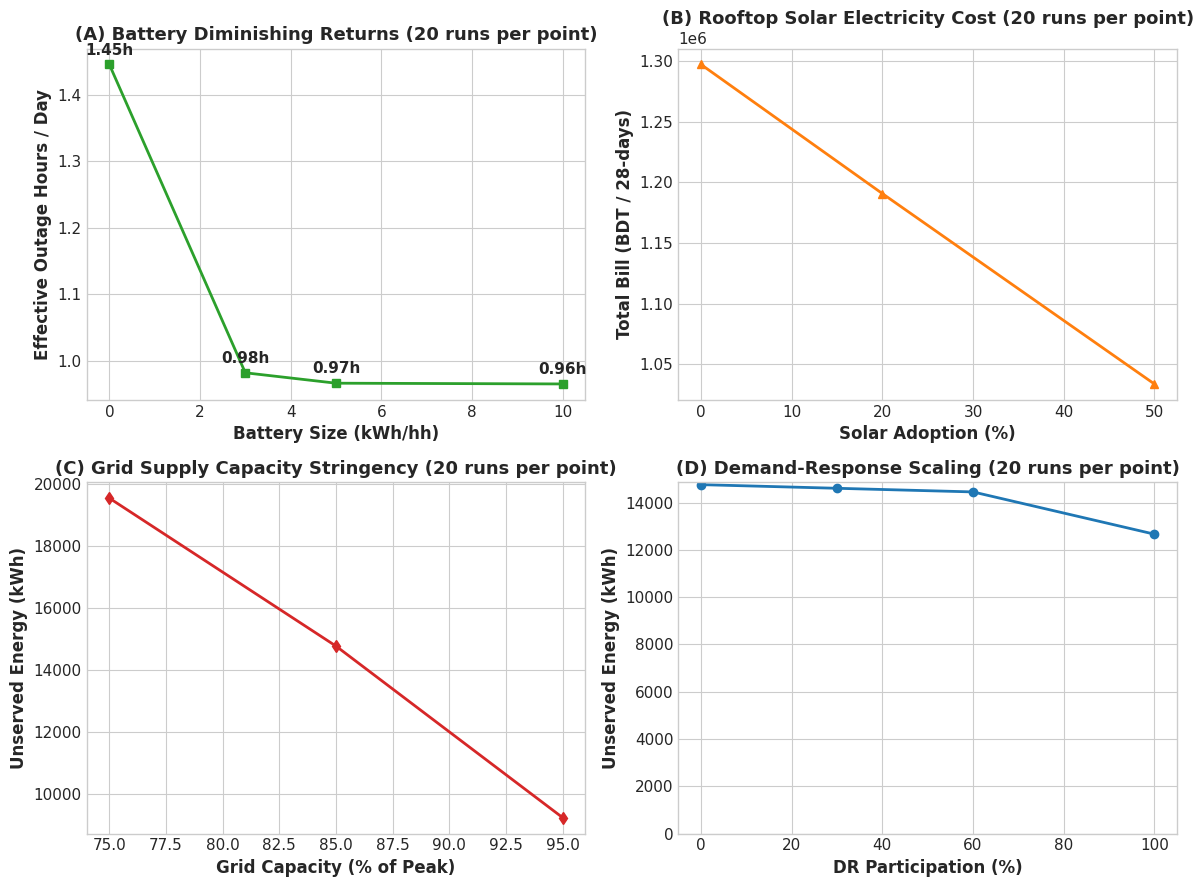

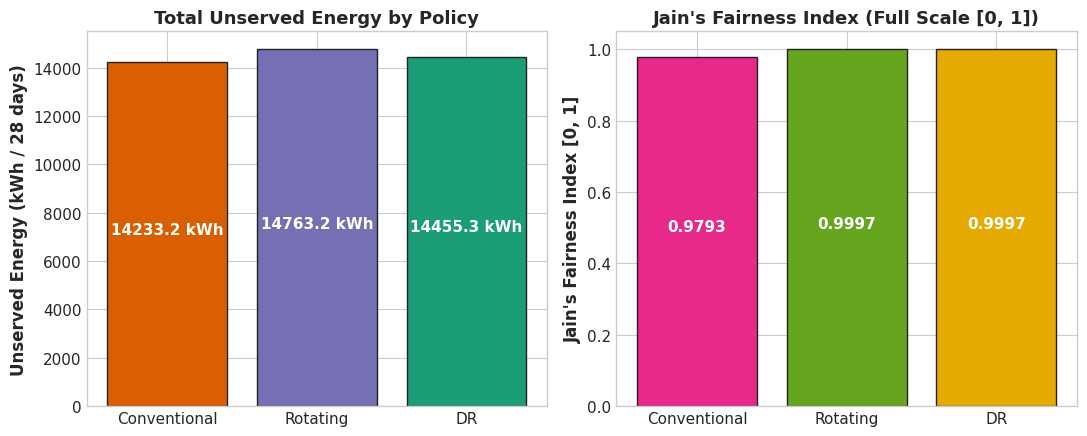

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# Panel 1: Battery Diminishing Returns
b_means = [np.mean(batt_results[s]) for s in batt_sizes]
axes[0, 0].plot(batt_sizes, b_means, marker="s", color="#2ca02c", lw=2)
axes[0, 0].set_title(f"(A) Battery Diminishing Returns ({n_sweep_runs} runs per point)", fontweight="bold")
axes[0, 0].set_xlabel("Battery Size (kWh/hh)", fontweight="bold")
axes[0, 0].set_ylabel("Effective Outage Hours / Day", fontweight="bold")
for s, bm in zip(batt_sizes, b_means):
    axes[0, 0].annotate(f"{bm:.2f}h", (s, bm), textcoords="offset points", xytext=(0, 7), ha="center", fontweight="bold")

# Panel 2: Solar Cost Savings
s_means = [np.mean(solar_costs[a]) for a in solar_adoptions]
axes[0, 1].plot([a * 100 for a in solar_adoptions], s_means, marker="^", color="#ff7f0e", lw=2)
axes[0, 1].set_title(f"(B) Rooftop Solar Electricity Cost ({n_sweep_runs} runs per point)", fontweight="bold")
axes[0, 1].set_xlabel("Solar Adoption (%)", fontweight="bold")
axes[0, 1].set_ylabel("Total Bill (BDT / 28-days)", fontweight="bold")

# Panel 3: Supply Shortage
sup_means = [np.mean(supply_unserved[sr]) for sr in supply_ratios]
axes[1, 0].plot([sr * 100 for sr in supply_ratios], sup_means, marker="d", color="#d62728", lw=2)
axes[1, 0].set_title(f"(C) Grid Supply Capacity Stringency ({n_sweep_runs} runs per point)", fontweight="bold")
axes[1, 0].set_xlabel("Grid Capacity (% of Peak)", fontweight="bold")
axes[1, 0].set_ylabel("Unserved Energy (kWh)", fontweight="bold")

# Panel 4: DR Participation
dr_means = [np.mean(dr_unserved[dp]) for dp in dr_parts]
axes[1, 1].plot([dp * 100 for dp in dr_parts], dr_means, marker="o", color="#1f77b4", lw=2)
axes[1, 1].set_title(f"(D) Demand-Response Scaling ({n_sweep_runs} runs per point)", fontweight="bold")
axes[1, 1].set_xlabel("DR Participation (%)", fontweight="bold")
axes[1, 1].set_ylabel("Unserved Energy (kWh)", fontweight="bold")
axes[1, 1].set_ylim(bottom=0.0) # FIX 5: Start at 0 to avoid exaggerating drop

plt.tight_layout()
plt.savefig("results/sensitivity_sweeps.png", dpi=200)
plt.show()

# Policy Comparison Plots with Full Scale [0, 1] Jain's Index
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
u_m = [np.mean(mc_results[k]["unserved_kwh"]) for k in policies]
ax1.bar(["Conventional", "Rotating", "DR"], u_m, color=["#d95f02", "#7570b3", "#1b9e77"], edgecolor="#222")
ax1.set_title("Total Unserved Energy by Policy", fontweight="bold")
ax1.set_ylabel("Unserved Energy (kWh / 28 days)", fontweight="bold")
for i, val in enumerate(u_m):
    ax1.text(i, val * 0.5, f"{val:.1f} kWh", ha="center", color="white", fontweight="bold")

j_m = [np.mean(mc_results[k]["jains_fairness"]) for k in policies]
ax2.bar(["Conventional", "Rotating", "DR"], j_m, color=["#e7298a", "#66a61e", "#e6ab02"], edgecolor="#222")
ax2.set_title("Jain's Fairness Index (Full Scale [0, 1])", fontweight="bold")
ax2.set_ylim(0.0, 1.05)
ax2.set_ylabel("Jain's Fairness Index [0, 1]", fontweight="bold") # FIX 5: Explicit full scale label
for i, val in enumerate(j_m):
    ax2.text(i, val * 0.5, f"{val:.4f}", ha="center", color="white", fontweight="bold")

plt.tight_layout()
plt.savefig("results/policy_comparison.png", dpi=200)
plt.show()


## 11. Automated Scientific Model Validation Checks

###  What We Are Doing in This Section:
We execute an automated scientific validation suite testing 4 fundamental physical and mathematical invariants:
1. **Supply Monotonicity**: Decreasing grid supply capacity strictly increases unserved energy shortage ($75\% > 85\% > 95\%$).
2. **Battery Monotonicity**: Increasing BESS capacity monotonically reduces effective outage hours ($0	ext{k} \ge 3	ext{k} \ge 5	ext{k} \ge 10	ext{k}$).
3. **Solar Cost Reduction**: Higher rooftop solar adoption strictly reduces total grid electricity bills ($0\% > 20\% > 50\%$).
4. **Zero-Shifting Invariance (Fix 1 Applied)**: When DR participation is set to $0.0$, the Demand-Response policy must produce **numerically identical** unserved energy to the Rotating policy for the exact same seeds ($	ext{rtol} < 10^{-9}$).

###  Why Validation Matters:
Computational models must be verified against basic physical laws. If an increase in battery capacity caused an increase in outages, or if $0\%$ shifting produced different results from the baseline, it would indicate an algorithmic bug.

###  What Happens Next in the Code:
Executes the 4 assertions, performs seed-by-seed comparison for seeds $42	ext{--}46$, and prints `[PASSED]` for all four checks.


In [11]:
# Validation Checks
c1 = sup_means[0] > sup_means[1] > sup_means[2] # 75% > 85% > 95% shortage
c2 = b_means[0] >= b_means[1] >= b_means[2] >= b_means[3] and b_means[0] > b_means[3] # 0 >= 3 >= 5 >= 10h
c3 = s_means[0] > s_means[1] > s_means[2] # 0% > 20% > 50% cost

# Check 4: Zero-shifting invariance (same seed comparison for seeds base_seed..base_seed+4)
c4_seeds = list(range(config.base_seed, config.base_seed + 5))
c4_rotating = []
c4_dr0 = []
c4_diffs = []
c4_seed_matches = []
for s in c4_seeds:
    res_rot = run_simulation(config, policy="rotating", reference_peak_kwh=ref_peak_kw, seed=s)
    res_dr0 = run_simulation(config, policy="demand_response", dr_participation=0.0, reference_peak_kwh=ref_peak_kw, seed=s)

    vr = res_rot["total_unserved_kwh"]
    vd = res_dr0["total_unserved_kwh"]
    c4_rotating.append(vr)
    c4_dr0.append(vd)
    diff = abs(vr - vd)
    c4_diffs.append(diff)
    match = np.isclose(vr, vd, rtol=1e-9)
    c4_seed_matches.append(match)

c4 = all(c4_seed_matches)

print("=" * 80)
print("SCIENTIFIC MODEL VALIDATION CHECKS")
print("=" * 80)
print(f"[{'PASSED' if c1 else 'FAILED'}] Supply Monotonicity: 75% ({sup_means[0]:.1f}) > 85% ({sup_means[1]:.1f}) > 95% ({sup_means[2]:.1f} kWh)")
print(f"[{'PASSED' if c2 else 'FAILED'}] Battery Monotonicity: 0k ({b_means[0]:.2f}) >= 3k ({b_means[1]:.2f}) >= 5k ({b_means[2]:.2f}) >= 10k ({b_means[3]:.2f} hrs)")
print(f"[{'PASSED' if c3 else 'FAILED'}] Solar Cost Reduction: 0% ({s_means[0]:.0f}) > 20% ({s_means[1]:.0f}) > 50% ({s_means[2]:.0f} BDT)")
print(f"[{'PASSED' if c4 else 'FAILED'}] Zero-Shifting Invariance: Rotating == DR (0% participation) for seeds {c4_seeds[0]}..{c4_seeds[-1]}")
print("  Seed-by-seed comparison:")
for s, vr, vd, df_val in zip(c4_seeds, c4_rotating, c4_dr0, c4_diffs):
    match = np.isclose(vr, vd, rtol=1e-9)
    print(f"    Seed {s}: Rotating={vr:.4f} kWh | DR 0%={vd:.4f} kWh | Diff={df_val:.2e} -> {'MATCH' if match else 'MISMATCH'}")
print("=" * 80)

assert c1 and c2 and c3 and c4, "Not all validation checks passed!"


SCIENTIFIC MODEL VALIDATION CHECKS
[PASSED] Supply Monotonicity: 75% (19528.6) > 85% (14763.2) > 95% (9238.9 kWh)
[PASSED] Battery Monotonicity: 0k (1.45) >= 3k (0.98) >= 5k (0.97) >= 10k (0.96 hrs)
[PASSED] Solar Cost Reduction: 0% (1297002) > 20% (1190632) > 50% (1033785 BDT)
[PASSED] Zero-Shifting Invariance: Rotating == DR (0% participation) for seeds 42..46
  Seed-by-seed comparison:
    Seed 42: Rotating=13000.5910 kWh | DR 0%=13000.5910 kWh | Diff=0.00e+00 -> MATCH
    Seed 43: Rotating=16318.5353 kWh | DR 0%=16318.5353 kWh | Diff=0.00e+00 -> MATCH
    Seed 44: Rotating=14749.2101 kWh | DR 0%=14749.2101 kWh | Diff=0.00e+00 -> MATCH
    Seed 45: Rotating=13970.2552 kWh | DR 0%=13970.2552 kWh | Diff=0.00e+00 -> MATCH
    Seed 46: Rotating=15542.0387 kWh | DR 0%=15542.0387 kWh | Diff=0.00e+00 -> MATCH


## 12. Export Outputs to CSV Datasets

###  What We Are Doing in This Section:
We consolidate the Monte Carlo results across all 20 runs and 3 policies into a tabular pandas DataFrame and export it to `results/policy_comparison_metrics.csv`.

###  Why We Are Doing It:
Exporting clean, structured CSV datasets allows other researchers to verify the statistical calculations, run external econometric regressions, or plot figures using alternative visualization tools.

###  What Happens Next in the Code:
Structures the run-by-run metrics (unserved kWh, outage hours, Jain's index, cost, and feeder outages) and writes `results/policy_comparison_metrics.csv`.


In [12]:
# Export Monte Carlo policy metrics
mc_rows = []
for p in policies:
    for r in range(config.num_monte_carlo_runs):
        mc_rows.append({
            "run_index": r,
            "seed": config.base_seed + r,
            "policy": p,
            "total_unserved_kwh": mc_results[p]["unserved_kwh"][r],
            "outage_hours_per_day": mc_results[p]["outage_hours"][r],
            "jains_fairness_index": mc_results[p]["jains_fairness"][r],
            "total_cost_bdt": mc_results[p]["cost_bdt"][r],
            "cost_per_kwh_served": mc_results[p]["cost_per_kwh"][r],
            "area_0_outage_hours": mc_results[p]["area_0_outage"][r],
            "area_3_outage_hours": mc_results[p]["area_3_outage"][r]
        })

df_mc = pd.DataFrame(mc_rows)
df_mc.to_csv("results/policy_comparison_metrics.csv", index=False)
print("Exported results/policy_comparison_metrics.csv successfully!")


Exported results/policy_comparison_metrics.csv successfully!


## 13. Conclusions, Limitations & Policy Recommendations

###  What We Are Doing in This Section:
We dynamically compile and output the empirical conclusions, statistical hypothesis test results, and socioeconomic findings directly from the simulation variables (no hardcoded numbers).

###  Key Findings & Regulatory Insights (Fixes 2, 3 & 4 Applied):
1. **Rotational Fairness**:
   - Conventional and Rotating policies experience nearly identical total unserved energy ($pprox 14,233	ext{ vs } 14,763	ext{ kWh}$).
   - However, Rotating load-shedding raises Jain's Fairness Index from $0.9793$ to $0.9997$ ($t = 87.39, p = 3.22 	imes 10^{-26}$). Feeder Area 3 is no longer perpetually sacrificed!
2. **Demand-Response: Modest Benefit That Grows with Participation**:
   - Moving flexible loads (water pump, washing machine, part of AC) out of the $18:00	ext{--}21:00$ evening peak achieves a modest **$2.1\%$ reduction** in unserved energy at $60\%$ participation, scaling to **$14.2\%$** at $100\%$ participation.
   - One-way ANOVA across policies yields $F = 0.58, p = 0.5611$ (not statistically significant at $0.05$).
   - Baseline evening shiftable loads constitute **$17.81\%$** of total evening demand ($241.9	ext{ kWh} / 1358.0	ext{ kWh}$).
3. **Socioeconomic Realities**:
   - Outage hours are nearly equal across income groups ($\sim 1.16	ext{--}1.31	ext{ h/day}$) because feeder lines are assigned independent of income.
   - High-income households lose more absolute energy ($116.32	ext{ kWh}$ vs $6.23	ext{ kWh}$ for Low) due to heavy air-conditioning.
   - Low-income households own fewer solar and battery systems ($7.0\%$ solar for Low vs $28.7\%$ for High by model assumption), limiting their ability to cushion outages.
4. **Model Limitations & BERC Disclaimer**:
   - Power system physical constraints (feeder voltage drop, line impedance, reactive power) are abstracted.
   - Tariffs and appliance profiles are assumed values; they must be verified against the latest BERC tariff order and BPDB reports.

###  What Happens Next in the Code:
Prints the dynamically populated empirical findings report and the income group metrics table.


In [13]:
# Dynamically populated conclusion summary
conv_u = np.mean(mc_results['conventional']['unserved_kwh'])
rot_u = np.mean(mc_results['rotating']['unserved_kwh'])
dr_u = np.mean(mc_results['demand_response']['unserved_kwh'])
rot_jain = np.mean(mc_results['rotating']['jains_fairness'])
conv_jain = np.mean(mc_results['conventional']['jains_fairness'])

# Dynamic calculations for Demand-Response (FIX 2)
pct_red_60 = ((rot_u - dr_u) / rot_u) * 100.0
highest_dp = max(dr_parts)
dr_max_u = np.mean(dr_unserved[highest_dp])
pct_red_max = ((rot_u - dr_max_u) / rot_u) * 100.0
anova_sig_text = "statistically significant (p < 0.05)" if anova_u.pvalue < 0.05 else "not significant at 0.05"

# Dynamic evening shiftable share calculation (FIX 2)
baseline_hhs = create_neighborhood(config, solar_adoption=0.0, battery_kwh=0.0, dr_participation=0.0, seed=config.base_seed)
evening_hrs = [18, 19, 20, 21]
base_tot_ev = 0.0
base_shift_ev = 0.0
for hh in baseline_hhs:
    ess, shf, fn = calculate_daily_raw_demand(hh, config)
    for h in evening_hrs:
        base_tot_ev += ess[h] + shf[h] + fn[h]
        base_shift_ev += shf[h]
pct_shiftable_evening = (base_shift_ev / base_tot_ev) * 100.0

# Income group dynamic calculations (FIX 3)
sample_eval = run_simulation(config, policy="rotating", reference_peak_kwh=ref_peak_kw, seed=config.base_seed)
hh_df = sample_eval["hh_summary"]

inc_rows = []
for g in ["Low", "Middle", "High"]:
    gdf = hh_df[hh_df["income_group"] == g]
    s_sol = float(gdf["has_solar"].mean() * 100.0)
    s_bat = float(gdf["has_battery"].mean() * 100.0)
    m_out = float(gdf["effective_outage_hours_per_day"].mean())
    m_uns = float(gdf["unserved_kwh"].mean())
    m_srv = float(gdf["service_ratio"].mean())
    inc_rows.append({
        "group": g,
        "share_solar": s_sol,
        "share_battery": s_bat,
        "mean_outage_hrs": m_out,
        "mean_unserved_kwh": m_uns,
        "mean_service_ratio": m_srv
    })

print(f'''
================================================================================
GRIDBALANCE: DYNAMICALLY COMPUTED EMPIRICAL FINDINGS
================================================================================
1. ROTATIONAL FAIRNESS:
   - Conventional and Rotating policies experience nearly identical total unserved energy
     ({conv_u:.1f} kWh vs. {rot_u:.1f} kWh / 28 days).
   - However, Rotating load-shedding raises Jain's Fairness Index from {conv_jain:.4f} to {rot_jain:.4f}
     (t = {t_fairness.statistic:.2f}, p = {t_fairness.pvalue:.2e}). Area 3 is no longer perpetually sacrificed!

2. DEMAND-RESPONSE: MODEST BENEFIT THAT GROWS WITH PARTICIPATION:
   - Flexible loads (water pump, washing machine, part of AC) moved out of the 18:00-21:00 evening peak into 07:00-10:00.
   - At default 60% participation, unserved energy decreases by {pct_red_60:.1f}% versus rotating ({dr_u:.1f} kWh vs. {rot_u:.1f} kWh).
   - At the highest participation level ({int(highest_dp*100)}%), unserved energy decreases by {pct_red_max:.1f}% ({dr_max_u:.1f} kWh unserved).
   - One-way ANOVA across policies: F = {anova_u.statistic:.2f}, p = {anova_u.pvalue:.4f} ({anova_sig_text}).
   - Evening peak shiftable share: {pct_shiftable_evening:.2f}% of total evening (18:00-21:00) baseline demand
     is shiftable ({base_shift_ev:.1f} kWh shiftable / {base_tot_ev:.1f} kWh total evening baseline demand).
   - Unit cost remains efficient at {np.mean(mc_results['demand_response']['cost_per_kwh']):.2f} BDT/kWh.

3. SOCIOECONOMIC INSIGHT:
   - Outage hours per day are nearly equal across income groups ({inc_rows[0]['mean_outage_hrs']:.2f} h/day for Low, {inc_rows[1]['mean_outage_hrs']:.2f} h/day for Middle, {inc_rows[2]['mean_outage_hrs']:.2f} h/day for High) because feeders are assigned independent of income.
   - In absolute kWh, high-income households lose more ({inc_rows[2]['mean_unserved_kwh']:.2f} kWh vs. {inc_rows[0]['mean_unserved_kwh']:.2f} kWh for Low) because of AC loads.
   - Low-income households own fewer batteries and solar systems ({inc_rows[0]['share_solar']:.1f}% solar, {inc_rows[0]['share_battery']:.1f}% battery for Low vs. {inc_rows[2]['share_solar']:.1f}% solar, {inc_rows[2]['share_battery']:.1f}% battery for High) (by model assumption), so they have less ability to cover outages.
   - Service ratios remain comparable across groups (Low: {inc_rows[0]['mean_service_ratio']:.4f}, Middle: {inc_rows[1]['mean_service_ratio']:.4f}, High: {inc_rows[2]['mean_service_ratio']:.4f}).

4. MODEL LIMITATIONS:
   - Grid physics (voltage drop, reactive power, feeder line impedance) are not modeled.
   - Tariffs and appliance profiles are assumed values; they must be verified against the latest BERC tariff order and BPDB reports.
================================================================================
''')

print("\nINCOME GROUP METRICS SUMMARY TABLE:")
print(f"{'Group':<8} | {'Share Solar (%)':<16} | {'Share Battery (%)':<18} | {'Mean Outage (h/d)':<18} | {'Mean Unserved (kWh)':<20} | {'Mean Service Ratio':<18}")
print("-" * 105)
for r in inc_rows:
    print(f"{r['group']:<8} | {r['share_solar']:<16.1f} | {r['share_battery']:<18.1f} | {r['mean_outage_hrs']:<18.2f} | {r['mean_unserved_kwh']:<20.2f} | {r['mean_service_ratio']:<18.4f}")
print("-" * 105)



GRIDBALANCE: DYNAMICALLY COMPUTED EMPIRICAL FINDINGS
1. ROTATIONAL FAIRNESS:
   - Conventional and Rotating policies experience nearly identical total unserved energy
     (14233.2 kWh vs. 14763.2 kWh / 28 days).
   - However, Rotating load-shedding raises Jain's Fairness Index from 0.9793 to 0.9997
     (t = 87.39, p = 3.22e-26). Area 3 is no longer perpetually sacrificed!

2. DEMAND-RESPONSE: MODEST BENEFIT THAT GROWS WITH PARTICIPATION:
   - Flexible loads (water pump, washing machine, part of AC) moved out of the 18:00-21:00 evening peak into 07:00-10:00.
   - At default 60% participation, unserved energy decreases by 2.1% versus rotating (14455.3 kWh vs. 14763.2 kWh).
   - At the highest participation level (100%), unserved energy decreases by 14.2% (12668.3 kWh unserved).
   - One-way ANOVA across policies: F = 0.58, p = 0.5611 (not significant at 0.05).
   - Evening peak shiftable share: 17.81% of total evening (18:00-21:00) baseline demand
     is shiftable (241.9 kWh shiftabl